Cell 1 — Load the data and set up folders

In [1]:
!pip -q install scanpy scipy

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scanpy as sc
from scipy.spatial import cKDTree

# Project folders
BASE_DIR = Path("/content/drive/MyDrive/spatial_transcriptomics")
RESULTS_DIR = BASE_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Prefer the QC-annotated file if it exists
QC_PATH = BASE_DIR / "xenium_breast_cancer_qc.h5ad"
ORIGINAL_PATH = BASE_DIR / "xenium_breast_cancer.h5ad"

DATA_PATH = QC_PATH if QC_PATH.exists() else ORIGINAL_PATH
adata = sc.read_h5ad(DATA_PATH)

print("Loaded:", DATA_PATH.name)
print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Results folder:", RESULTS_DIR)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Loaded: xenium_breast_cancer_qc.h5ad
Cells: 167780
Genes: 313
Results folder: /content/drive/MyDrive/spatial_transcriptomics/results


Cell 2 — Check marker genes and spatial coordinates

In [2]:
coords = np.asarray(adata.obsm["spatial"], dtype=float)

assert coords.shape == (adata.n_obs, 2), "Expected two spatial coordinates per cell."
assert np.isfinite(coords).all(), "Some spatial coordinates are missing or invalid."

markers = ["EPCAM", "KRT8", "CD3D", "CD3E"]

missing_markers = [gene for gene in markers if gene not in adata.var_names]
assert not missing_markers, f"Missing required genes: {missing_markers}"

print("All required marker genes are available.")
print("Coordinate ranges:")
print("X:", coords[:, 0].min(), "to", coords[:, 0].max())
print("Y:", coords[:, 1].min(), "to", coords[:, 1].max())

All required marker genes are available.
Coordinate ranges:
X: 2.1325160980224607 to 7523.086865234375
Y: 1.3671555936336517 to 5476.26611328125


Cell 3 — Define the two cell groups

In [3]:
def expression_vector(gene):
    """Return one expression value per cell, including for sparse matrices."""
    values = adata[:, gene].X

    if hasattr(values, "toarray"):
        values = values.toarray()

    return np.asarray(values).ravel()


epcam = expression_vector("EPCAM")
krt8 = expression_vector("KRT8")
cd3d = expression_vector("CD3D")
cd3e = expression_vector("CD3E")

epithelial_mask = (epcam > 0) & (krt8 > 0)
tcell_mask = (cd3d > 0) & (cd3e > 0)

# Exclude cells meeting both definitions from the exclusive-group comparison
overlap_mask = epithelial_mask & tcell_mask
epithelial_only_mask = epithelial_mask & ~tcell_mask
tcell_only_mask = tcell_mask & ~epithelial_mask

group_summary = pd.DataFrame({
    "group": [
        "Epithelial-associated (both markers)",
        "T-cell-associated (both markers)",
        "Both definitions",
        "Epithelial-associated only",
        "T-cell-associated only",
    ],
    "cell_count": [
        int(epithelial_mask.sum()),
        int(tcell_mask.sum()),
        int(overlap_mask.sum()),
        int(epithelial_only_mask.sum()),
        int(tcell_only_mask.sum()),
    ],
})

print(group_summary.to_string(index=False))
group_summary.to_csv(
    RESULTS_DIR / "cell_neighborhood_group_counts.csv",
    index=False
)

                               group  cell_count
Epithelial-associated (both markers)       80057
    T-cell-associated (both markers)       15003
                    Both definitions        1944
          Epithelial-associated only       78113
              T-cell-associated only       13059


Cell 4 — Calculate nearest-neighbor distances

In [4]:
epithelial_coords = coords[epithelial_only_mask]
tcell_coords = coords[tcell_only_mask]

assert len(epithelial_coords) > 0, "No epithelial-associated cells available."
assert len(tcell_coords) > 0, "No T-cell-associated cells available."

# Build a spatial search tree for epithelial-associated cells
epithelial_tree = cKDTree(epithelial_coords)

# For each T-cell-associated cell, find its nearest epithelial-associated cell
distances, nearest_indices = epithelial_tree.query(tcell_coords, k=1)

distance_summary = pd.DataFrame({
    "metric": [
        "T-cell-only cell count",
        "Epithelial-only cell count",
        "Median nearest epithelial distance",
        "Mean nearest epithelial distance",
        "25th percentile distance",
        "75th percentile distance",
    ],
    "value": [
        len(tcell_coords),
        len(epithelial_coords),
        np.median(distances),
        np.mean(distances),
        np.percentile(distances, 25),
        np.percentile(distances, 75),
    ],
})

print(distance_summary.to_string(index=False))
distance_summary.to_csv(
    RESULTS_DIR / "nearest_epithelial_distance_summary.csv",
    index=False
)

# Save individual cell distances for later analysis
distance_table = pd.DataFrame({
    "tcell_index_in_adata": np.flatnonzero(tcell_only_mask),
    "nearest_epithelial_distance": distances,
    "nearest_epithelial_index_in_adata":
        np.flatnonzero(epithelial_only_mask)[nearest_indices],
})

distance_table.to_csv(
    RESULTS_DIR / "tcell_nearest_epithelial_distances.csv",
    index=False
)

                            metric        value
            T-cell-only cell count 13059.000000
        Epithelial-only cell count 78113.000000
Median nearest epithelial distance    33.136227
  Mean nearest epithelial distance    39.116509
          25th percentile distance    19.858915
          75th percentile distance    52.723750


Cell 5 — Plot the distance distribution

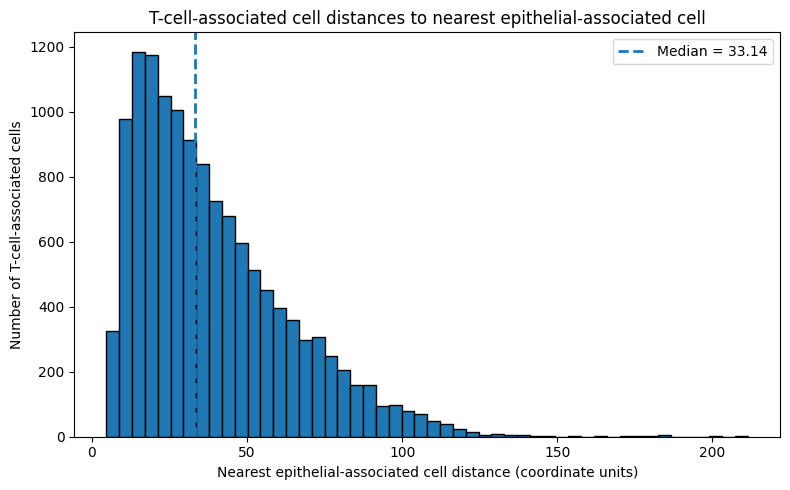

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(distances, bins=50, edgecolor="black")
plt.axvline(
    np.median(distances),
    linestyle="--",
    linewidth=2,
    label=f"Median = {np.median(distances):.2f}"
)

plt.xlabel("Nearest epithelial-associated cell distance (coordinate units)")
plt.ylabel("Number of T-cell-associated cells")
plt.title("T-cell-associated cell distances to nearest epithelial-associated cell")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "tcell_nearest_epithelial_distance_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Cell 6 — Visualize both groups on the tissue map

/tmp/ipykernel_1202/871736125.py:29: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/tmp/ipykernel_1202/871736125.py:31: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


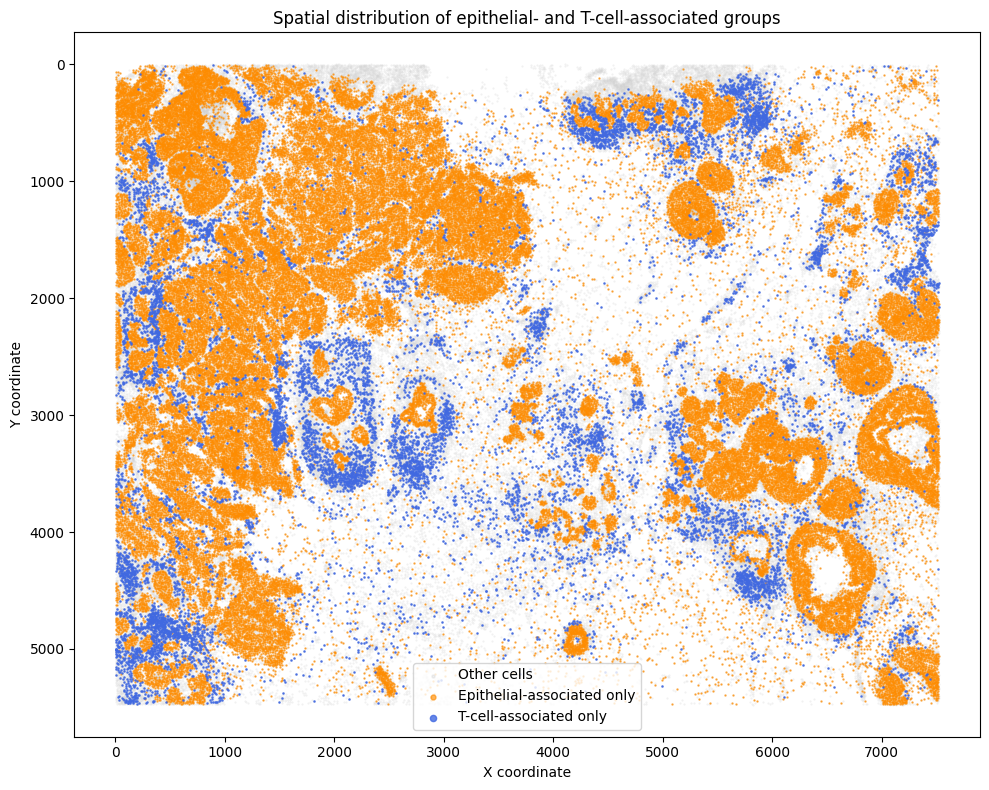

In [6]:
plt.figure(figsize=(10, 8))

# Background tissue cells
plt.scatter(
    coords[:, 0], coords[:, 1],
    s=0.2, c="lightgray", alpha=0.35,
    label="Other cells", rasterized=True
)

plt.scatter(
    coords[epithelial_only_mask, 0],
    coords[epithelial_only_mask, 1],
    s=0.5, c="darkorange", alpha=0.65,
    label="Epithelial-associated only", rasterized=True
)

plt.scatter(
    coords[tcell_only_mask, 0],
    coords[tcell_only_mask, 1],
    s=0.8, c="royalblue", alpha=0.8,
    label="T-cell-associated only", rasterized=True
)

plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.title("Spatial distribution of epithelial- and T-cell-associated groups")
plt.gca().invert_yaxis()
plt.legend(markerscale=5)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "epithelial_tcell_spatial_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Cell 7 — Run a local label-permutation test

In [11]:
# Reproducibility settings
RANDOM_SEED = 42
N_PERMUTATIONS = 100

# Use the union of the two exclusive groups
pool_mask = epithelial_only_mask | tcell_only_mask
pool_coords = coords[pool_mask]

# Labels: 1 = epithelial-associated, 0 = T-cell-associated
pool_labels = epithelial_only_mask[pool_mask].astype(int)

# Divide the tissue into a 20 x 20 grid based on coordinate ranges
N_GRID_BINS = 20

x_edges = np.linspace(coords[:, 0].min(), coords[:, 0].max(), N_GRID_BINS + 1)
y_edges = np.linspace(coords[:, 1].min(), coords[:, 1].max(), N_GRID_BINS + 1)

x_bin = np.clip(
    np.digitize(pool_coords[:, 0], x_edges) - 1,
    0, N_GRID_BINS - 1
)
y_bin = np.clip(
    np.digitize(pool_coords[:, 1], y_edges) - 1,
    0, N_GRID_BINS - 1
)

# Collect indices belonging to each spatial bin
bin_groups = {}
for i, key in enumerate(zip(x_bin, y_bin)):
    bin_groups.setdefault(key, []).append(i)

bin_indices = [
    np.asarray(indices, dtype=int)
    for indices in bin_groups.values()
]

print("Spatial bins containing at least one selected cell:", len(bin_indices))
print("Total cells in permutation pool:", len(pool_coords))
print("Grid size:", N_GRID_BINS, "x", N_GRID_BINS)

Spatial bins containing at least one selected cell: 400
Total cells in permutation pool: 91172
Grid size: 20 x 20


In [12]:
rng = np.random.default_rng(RANDOM_SEED)

observed_epithelial = pool_coords[pool_labels == 1]
observed_tcells = pool_coords[pool_labels == 0]

assert len(observed_epithelial) > 0 and len(observed_tcells) > 0

observed_tree = cKDTree(observed_epithelial)
observed_tcell_distances, _ = observed_tree.query(observed_tcells, k=1)
observed_median = float(np.median(observed_tcell_distances))

null_medians = []

for permutation in range(N_PERMUTATIONS):
    shuffled_labels = pool_labels.copy()

    # Shuffle labels separately inside each spatial bin
    for indices in bin_indices:
        shuffled_labels[indices] = rng.permutation(shuffled_labels[indices])

    perm_epithelial = pool_coords[shuffled_labels == 1]
    perm_tcells = pool_coords[shuffled_labels == 0]

    # Skip only if a group is absent in the randomized data
    if len(perm_epithelial) == 0 or len(perm_tcells) == 0:
        continue

    perm_tree = cKDTree(perm_epithelial)
    perm_distances, _ = perm_tree.query(perm_tcells, k=1)

    null_medians.append(float(np.median(perm_distances)))

null_medians = np.asarray(null_medians)

assert len(null_medians) > 0, "No valid permutations were produced."

# One-sided empirical test: are observed distances unusually small?
p_value_smaller = (
    1 + np.sum(null_medians <= observed_median)
) / (1 + len(null_medians))

print(f"Observed median distance: {observed_median:.3f}")
print(f"Mean null median distance: {null_medians.mean():.3f}")
print(f"Null 2.5th percentile: {np.percentile(null_medians, 2.5):.3f}")
print(f"Null 97.5th percentile: {np.percentile(null_medians, 97.5):.3f}")
print(f"Valid permutations: {len(null_medians)}")
print(f"One-sided empirical p-value (smaller distances): {p_value_smaller:.4f}")

permutation_summary = pd.DataFrame({
    "observed_median_distance": [observed_median],
    "mean_null_median_distance": [null_medians.mean()],
    "null_2_5_percentile": [np.percentile(null_medians, 2.5)],
    "null_97_5_percentile": [np.percentile(null_medians, 97.5)],
    "valid_permutations": [len(null_medians)],
    "grid_bins_per_axis": [N_GRID_BINS],
    "empirical_p_value_smaller": [p_value_smaller],
})

permutation_summary.to_csv(
    RESULTS_DIR / "local_permutation_summary.csv",
    index=False
)

pd.DataFrame({"null_median_distance": null_medians}).to_csv(
    RESULTS_DIR / "local_permutation_null_distances.csv",
    index=False
)

Observed median distance: 33.136
Mean null median distance: 13.229
Null 2.5th percentile: 13.105
Null 97.5th percentile: 13.362
Valid permutations: 100
One-sided empirical p-value (smaller distances): 1.0000


In [13]:
# Test whether the observed median is larger than the randomized medians
p_value_larger = (
    1 + np.sum(null_medians >= observed_median)
) / (1 + len(null_medians))

print(f"Observed median: {observed_median:.3f}")
print(f"Mean randomized median: {null_medians.mean():.3f}")
print(f"Randomized medians >= observed: "
      f"{np.sum(null_medians >= observed_median)}")
print(f"Empirical p-value (larger distances): {p_value_larger:.4f}")

Observed median: 33.136
Mean randomized median: 13.229
Randomized medians >= observed: 0
Empirical p-value (larger distances): 0.0099


In [14]:
def run_local_permutation_test(n_bins, n_permutations=100, seed=42):
    # Recalculate spatial bins for this grid resolution
    x_edges = np.linspace(coords[:, 0].min(), coords[:, 0].max(),
                          n_bins + 1)
    y_edges = np.linspace(coords[:, 1].min(), coords[:, 1].max(),
                          n_bins + 1)

    x_bin = np.clip(np.digitize(pool_coords[:, 0], x_edges) - 1,
                    0, n_bins - 1)
    y_bin = np.clip(np.digitize(pool_coords[:, 1], y_edges) - 1,
                    0, n_bins - 1)

    bin_groups = {}
    for i, key in enumerate(zip(x_bin, y_bin)):
        bin_groups.setdefault(key, []).append(i)

    groups = [np.asarray(v, dtype=int) for v in bin_groups.values()]
    rng = np.random.default_rng(seed)
    null = []

    for _ in range(n_permutations):
        labels = pool_labels.copy()

        for indices in groups:
            labels[indices] = rng.permutation(labels[indices])

        epi = pool_coords[labels == 1]
        tc = pool_coords[labels == 0]

        if len(epi) == 0 or len(tc) == 0:
            continue

        tree = cKDTree(epi)
        d, _ = tree.query(tc, k=1)
        null.append(np.median(d))

    null = np.asarray(null)
    p_larger = (1 + np.sum(null >= observed_median)) / (1 + len(null))

    return {
        "grid": f"{n_bins}x{n_bins}",
        "bins_with_cells": len(groups),
        "observed_median": observed_median,
        "mean_null_median": null.mean(),
        "null_2_5_percentile": np.percentile(null, 2.5),
        "null_97_5_percentile": np.percentile(null, 97.5),
        "p_value_larger": p_larger,
        "valid_permutations": len(null),
    }


sensitivity_results = pd.DataFrame([
    run_local_permutation_test(10),
    run_local_permutation_test(20),
    run_local_permutation_test(40),
])

print(sensitivity_results.to_string(index=False))

sensitivity_results.to_csv(
    RESULTS_DIR / "grid_sensitivity_analysis.csv",
    index=False
)

 grid  bins_with_cells  observed_median  mean_null_median  null_2_5_percentile  null_97_5_percentile  p_value_larger  valid_permutations
10x10              100        33.136227         11.610460            11.548233             11.672576        0.009901                 100
20x20              400        33.136227         13.229176            13.104878             13.361533        0.009901                 100
40x40             1581        33.136227         16.902875            16.660904             17.142991        0.009901                 100


Cell 8 — Plot the null comparison

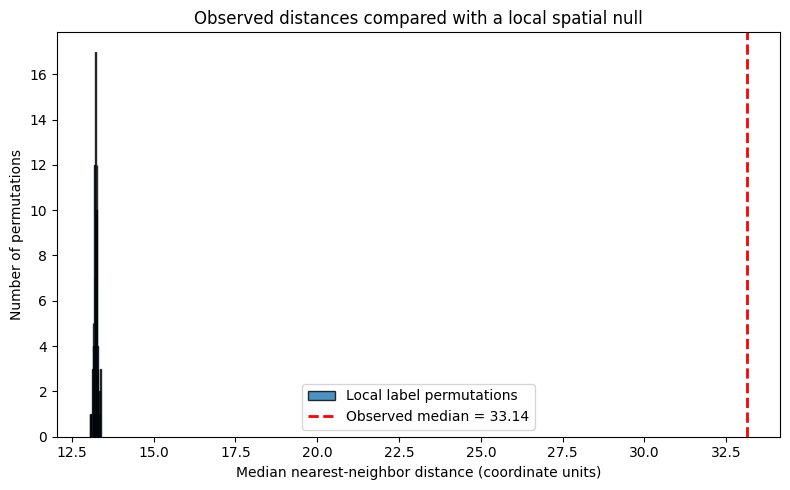

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(
    null_medians,
    bins=20,
    edgecolor="black",
    alpha=0.8,
    label="Local label permutations"
)

plt.axvline(
    observed_median,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Observed median = {observed_median:.2f}"
)

plt.xlabel("Median nearest-neighbor distance (coordinate units)")
plt.ylabel("Number of permutations")
plt.title("Observed distances compared with a local spatial null")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "local_permutation_distance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Cell 9 — Write a reproducibility manifest

In [10]:
manifest = {
    "notebook": "04_cell_neighborhoods.ipynb",
    "input_file": DATA_PATH.name,
    "n_cells": int(adata.n_obs),
    "n_genes": int(adata.n_vars),
    "random_seed": RANDOM_SEED,
    "n_permutations_requested": N_PERMUTATIONS,
    "n_permutations_valid": int(len(null_medians)),
    "grid_bins_per_axis": N_GRID_BINS,
    "epithelial_definition": "EPCAM > 0 and KRT8 > 0",
    "tcell_definition": "CD3D > 0 and CD3E > 0",
    "overlap_handling": "Cells meeting both definitions excluded from exclusive-group distance analysis",
    "distance_unit": "Dataset coordinate units; physical scale not assumed",
    "observed_median_distance": observed_median,
    "mean_null_median_distance": float(null_medians.mean()),
    "empirical_p_value_smaller": float(p_value_smaller),
    "interpretation_note": (
        "Exploratory spatial association analysis. Marker-based groups are "
        "not definitive cell-type labels. Local label permutations preserve "
        "group counts within grid bins but do not fully model tissue architecture "
        "or establish cell-cell interaction."
    ),
}

manifest_path = RESULTS_DIR / "cell_neighborhood_analysis_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("Saved analysis manifest:", manifest_path)
print("All neighborhood analysis cells completed.")

Saved analysis manifest: /content/drive/MyDrive/spatial_transcriptomics/results/cell_neighborhood_analysis_manifest.json
All neighborhood analysis cells completed.
